# I. Import thu vien 

In [153]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [154]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import datetime
import seaborn as sns
import plotly.express as px
import inspect
import time
import warnings
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tools.sm_exceptions import ConvergenceWarning
warnings.simplefilter('ignore', ConvergenceWarning)
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import TimeSeriesSplit
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.ar_model import AutoReg
%matplotlib inline

# II. Doc va xu ly du lieu 

In [155]:
# Doc file csv vào DataFrame

df = pd.read_csv('Data/hanoi-aqi-weather-data.csv') 

# Chuyen cot Lcal Time sang dang DateTime
df['Local Time'] = pd.to_datetime(df['Local Time'])

# Chuyen cot Local Time thanh index
df.set_index('Local Time', inplace=True) # True thay doi truc tiep tren DataFrame bnan dau

df



,UTC Time,City,Country Code,Timezone,AQI,CO,NO2,O3,PM10,PM25,SO2,Clouds,Precipitation,Pressure,Relative Humidity,Temperature,UV Index,Wind Speed
Local Time,,,,,,,,,,,,,,,,,,
2023-03-08 00:00:00,2023-03-07T17:00:00,Hanoi,VN,Asia/Ho_Chi_Minh,131,170.6,29.3,53.3,58.8,47.00,67.3,91,0.0,1016,86,21.2,0.0,2.00
2023-03-08 01:00:00,2023-03-07T18:00:00,Hanoi,VN,Asia/Ho_Chi_Minh,126,158.7,25.0,54.0,56.3,45.00,65.0,100,0.0,1016,89,21.1,0.0,2.00
2023-03-08 02:00:00,2023-03-07T19:00:00,Hanoi,VN,Asia/Ho_Chi_Minh,118,150.2,21.7,55.0,52.5,42.00,65.7,100,0.0,1016,90,20.9,0.0,1.66
2023-03-08 03:00:00,2023-03-07T20:00:00,Hanoi,VN,Asia/Ho_Chi_Minh,126,141.6,18.3,56.0,56.3,45.00,66.3,100,0.0,1016,91,20.7,0.0,1.33
2023-03-08 04:00:00,2023-03-07T21:00:00,Hanoi,VN,Asia/Ho_Chi_Minh,118,133.1,15.0,57.0,52.5,42.00,67.0,100,0.0,1015,92,20.5,0.0,1.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-03-07 20:00:00,2024-03-07T13:00:00,Hanoi,VN,Asia/Ho_Chi_Minh,193,6738.4,36.7,21.4,139.3,87.86,12.0,100,0.0,1014,71,21.5,0.0,1.00
2024-03-07 21:00:00,2024-03-07T14:00:00,Hanoi,VN,Asia/Ho_Chi_Minh,173,6693.2,29.3,19.5,140.6,73.00,6.0,100,0.0,1015,75,21.1,0.0,1.00
2024-03-07 22:00:00,2024-03-07T15:00:00,Hanoi,VN,Asia/Ho_Chi_Minh,241,504.0,108.0,18.4,167.0,124.00,116.0,100,0.0,1016,80,20.6,0.0,1.00


# 2.1 Tao chuoi thoi gian nong do PM2.5 theo ngay

In [156]:
df_pm25_hourly = df['PM25'].copy()


df_pm25_daily = df_pm25_hourly.resample('D').agg('mean')

df_pm25 = df_pm25_daily

df_pm25

Local Time
2023-03-08     51.208333
2023-03-09     83.125000
2023-03-10     89.416667
2023-03-11     58.416667
2023-03-12     66.333333
                 ...    
2024-03-04     66.708333
2024-03-05    104.584583
2024-03-06     75.343333
2024-03-07     54.213750
2024-03-08     62.000000
Freq: D, Name: PM25, Length: 367, dtype: float64

# 2.2 Thong tin chuoi thoi gian

In [157]:
df_pm25.info()

<class 'pandas.core.series.Series'>
DatetimeIndex: 367 entries, 2023-03-08 to 2024-03-08
Freq: D
Series name: PM25
Non-Null Count  Dtype  
--------------  -----  
367 non-null    float64
dtypes: float64(1)
memory usage: 5.7 KB


# III Kham pha du lieu

# 3.1 Kiem tra tinh dung cua du lieu ( Kiem dinh Augmented Dickey-Fuller)

In [158]:
adf_result = adfuller(df_pm25)

print ('ADF Statistic: ', adf_result[0])
print ('p-value: ', adf_result[1])
print ('Critical Values: ', adf_result[4])

ADF Statistic:  -4.1120966137945585
p-value:  0.000924882046265438
Critical Values:  {'1%': np.float64(-3.448544133483233), '5%': np.float64(-2.8695574079525565), '10%': np.float64(-2.5710411593052713)}


- ADF :
    + H0 : chuoi co nghiem don vi , ko dung
    + H1: chuoi ko co nghiem don vi, dung

- ADF statics : Thong ke kiem dinh 
  + mang gia tri am dung kiem tra xem  chuoi  du lieu co nghiem don vi hay ( ko dung )  hay ko 
  + gia tri cang am thi cang co bang chung ung ho chuoi dung

- p-value : Gia tri xac suat
    + p-value < 0.05 -> bao bo H0 co bang chung chuoi dung
    + p-value >= 0.05 -> chua co du bang chung bac bo H0 -> ch the ket luan chuoi dung
- Critical Value : Gia tri toi han
    + cac nguong de so sanh voi ADF Statics
        


 ADF statics < all Critical Value  va p - value < 0.05 
 -> Bac bo H0 -> chuoi co tinh dung

# 3.2 Ve bieu do nong do PM2.5 theo ngay

<Axes: title={'center': 'PM2.5 Level in Hanoi'}, xlabel='Date', ylabel='PM2.5 Level '>

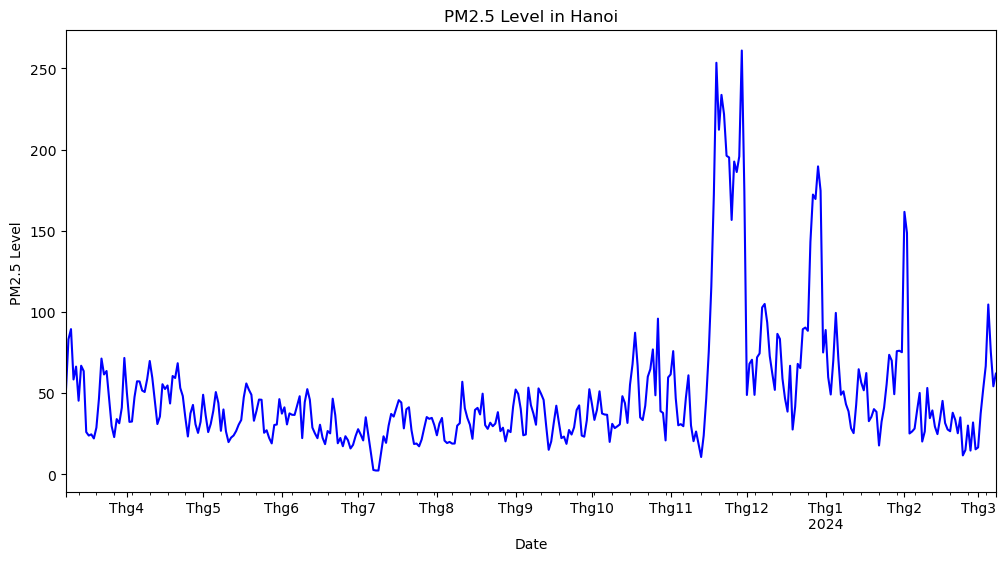

In [159]:
fig   = plt.figure(figsize=(12, 6))
df_pm25.plot(xlabel = "Date",
             ylabel = "PM2.5 Level ",
             title = "PM2.5 Level in Hanoi",
             color = "blue",)

# 3.3 Ve bieu do ACF va PACF

Text(0.5, 1.0, 'Hanoi PM2.5 Readings, ACF')

<Figure size 1500x1000 with 0 Axes>

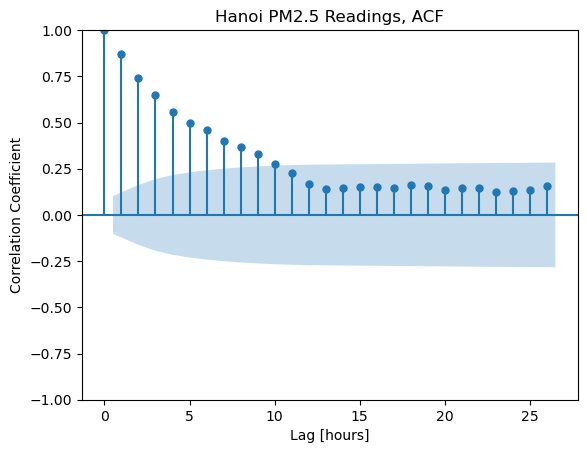

In [160]:
fig = plt.figure(figsize=(15, 10))
plot_acf(df_pm25)
plt.xlabel("Lag [hours]")
plt.ylabel("Correlation Coefficient")
plt.title("Hanoi PM2.5 Readings, ACF")

Bieu do ACF : 
    + Cho thay he so tuong quan giua chuoi PM2.5 va cac gia tri tre (lag)
    + Vai do tre dau tien co tu tuong quan duong cao , cho thay gia tri hien tai tuong quan manh voi cac gia tri ngay truoc do
    + Anh huong cua cac gia tri trong qua khu den gia tri hien tai yeu dan khi khoang cach thoi gian tang len
- Vung to mau xanh bieu thi khoang tin cay 95% 
    + CT : +/- 1.96/Can(N)  (N la so luong quan sat)
    + Nam trong khoang tin cay -> chu du bang chung ve tuong quan khac 0 
    + Nam ngoai : Co tuong quan duong dang ke va co du bang chung tuong quan khac 0 
    


Text(0.5, 1.0, 'Hanoi PM2.5 Readings, PACF')

<Figure size 1500x1000 with 0 Axes>

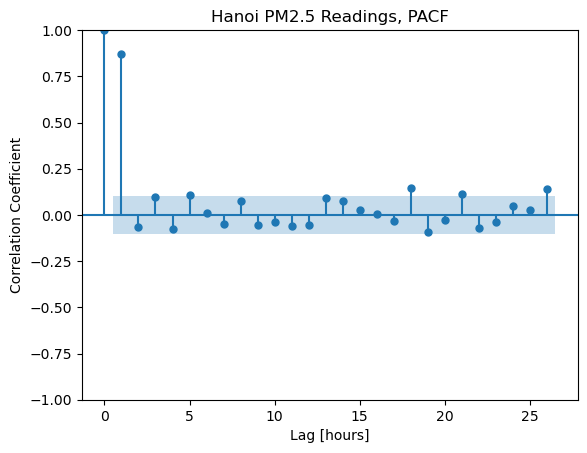

In [161]:
fig = plt.figure(figsize=(15, 10))
plot_pacf(df_pm25)
plt.xlabel("Lag [hours]")
plt.ylabel("Correlation Coefficient")
plt.title("Hanoi PM2.5 Readings, PACF")

Bieu do PACF : 
    + The hien he so tuong quan rieng phan giua chuoi PM2.5 va cac gia tri tre cua no, sau khi loai bo tuyen tinh cua cac do tre trung gian
    + Bieu do giam manh sau do tre dau tien, voi cac dinh dang ke o do tre 1 va 2
    + Sau do tre 2 cac he so nam trong khoang tin cay cho thay su phu thuoc ko con dang ke 
    + Goi y 1 qua trinh AR(2), trong do gia tri hien tai chu yeu chiu anh huong 2 gia tri truoc do 

# IV. Chia du lieu 

# 4.1 Chia du lieu thanh tap huan luyen va tập kiểm tra 

In [162]:
int(len(df_pm25)) * 0.8

293.6

In [163]:
cutoff_test = int(len(df_pm25)* 0.8) 
df_pm25_train = df_pm25.iloc[:cutoff_test]
df_pm25_test = df_pm25.iloc[cutoff_test:]
print("df_pm25_train shape:", df_pm25_train.shape)
print("df_pm25_test shape:", df_pm25_test.shape)

df_pm25_train shape: (293,)
df_pm25_test shape: (74,)


## 4.2. Kiểm tra tính dừng trên tập huấn luyện

In [164]:
# Thực hiện kiểm định ADF (kiểm tra tính dừng)
adf_result = adfuller(df_pm25_train)
print('ADF Statistic:', adf_result[0])
print('p-value:', adf_result[1])
print('Critical Values:', adf_result[4])

ADF Statistic: -2.612190880574396
p-value: 0.09050374592428312
Critical Values: {'1%': np.float64(-3.4540076534999957), '5%': np.float64(-2.8719557347997178), '10%': np.float64(-2.5723200648758366)}


Có thể thấy p-value lớn hơn mức ý nghĩa 5%, nghĩa là không thể bác bỏ giả thuyết không (H0). Nói cách khác, dữ liệu huấn luyện không có tính dừng.

Mô hình ARIMA thường hiệu quả hơn khi áp dụng cho chuỗi thời gian có tính dừng. Vì vậy, kỹ thuật lấy sai phân (differencing) sẽ được sử dụng trong mô hình ARIMA.

# V. Xây dựng mô hình

## 5.1. Mô hình cơ sở (Baseline)

In [165]:
df_pm25_train_mean = df_pm25_train.mean()
df_pm25_pred_baseline = pd.Series(df_pm25_train_mean, index=df_pm25_test.index)
mae_baseline = mean_absolute_error(df_pm25_test, df_pm25_pred_baseline)

print("Mean P2 Reading:", round(df_pm25_train_mean, 2))
print("Baseline Test MAE:", round(mae_baseline, 2))

Mean P2 Reading: 47.64
Baseline Test MAE: 27.21


Baseline dùng giá trị trung bình của tập huấn luyện để dự đoán mọi ngày trong tập kiểm tra. MAE của baseline và MAE của ARIMA cần được tính trên cùng tập kiểm tra để so sánh công bằng.

5.2 Thu nghiem cac mo hinh


Ở phần này, tôi sẽ thử nghiệm mô hình ARIMA(p, d, q) với các bộ tham số khác nhau.
- p: Số quan sát trễ được đưa vào mô hình (bậc tự hồi quy – AR).

- d: Số lần lấy sai phân cần thiết để chuỗi đạt tính dừng.

- q: Số sai số dự báo trễ được đưa vào mô hình (bậc trung bình trượt – MA).

Vì tập huấn luyện không có tính dừng, tham số d được cố định bằng 1 trong mọi lần thử.

### 5.2.1. Khai báo danh sách tham số

In [166]:
p_params = range(0, 8, 1)
q_params = range(0, 3, 1)
list(p_params)

[0, 1, 2, 3, 4, 5, 6, 7]

### 5.2.2. Chọn tham số ARIMA bằng MAE trên tập train (cách ban đầu)

Ở cách ban đầu, thử từng cấu hình `(p, 1, q)`, dự đoán ngay trên tập train rồi tính MAE. Cấu hình có MAE train thấp nhất được chọn. Vì đánh giá trên chính dữ liệu đã dùng để fit, điểm này có thể lạc quan; phần test vẫn được giữ riêng để đánh giá cuối cùng.

In [167]:
mae_grid_original = {p: [] for p in p_params}
grid_rows_original = []

for p in p_params:
    for q in q_params:
        order = (p, 1, q)
        fitted = ARIMA(df_pm25_train, order=order).fit()
        train_pred = fitted.predict()
        train_mae = mean_absolute_error(df_pm25_train, train_pred)
        mae_grid_original[p].append(train_mae)
        grid_rows_original.append({"order": order, "train_mae": train_mae})

original_results_df = pd.DataFrame(grid_rows_original).sort_values("train_mae")
best_order_original = original_results_df.iloc[0]["order"]
print("Best order (train MAE):", best_order_original)
print("Best train MAE:", round(original_results_df.iloc[0]["train_mae"], 2))

d:\App_Dowloaded\Anaconda\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'


Best order (train MAE): (5, 1, 1)
Best train MAE: 11.64


### 5.2.3. Bảng MAE trên tập train

In [168]:
mae_df_original = pd.DataFrame(mae_grid_original, index=list(q_params))
mae_df_original.index.name = "q"
mae_df_original.columns.name = "p"
mae_df_original.round(4)

p,0,1,2,3,4,5,6,7
q,,,,,,,,
0,12.1038,12.1008,12.0566,12.0223,11.8841,11.8349,11.8152,11.7666
1,12.0999,11.7167,11.7254,11.7141,11.7162,11.6378,11.7871,11.7893
2,12.0196,11.7247,11.6989,11.6990,11.6914,11.6501,11.6551,11.7540


Cấu hình được chọn là cấu hình có MAE thấp nhất trên chính tập train. Đây là cách chọn tham số ban đầu; MAE train chỉ dùng để lựa chọn, không thay thế MAE trên tập test.

### 5.2.4. Chẩn đoán phần dư

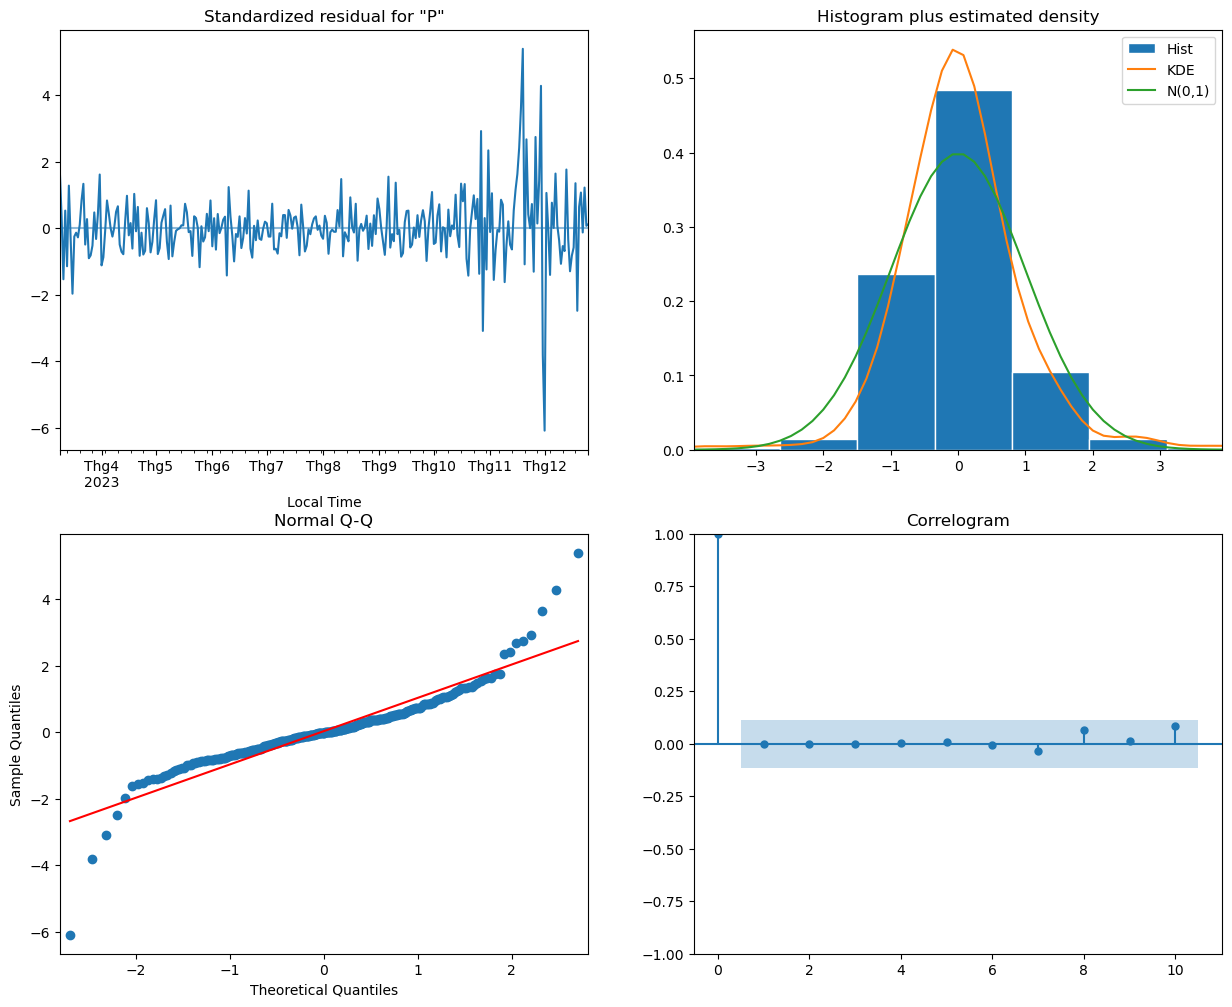

In [169]:
model_original = ARIMA(df_pm25_train, order=best_order_original)
results_original = model_original.fit()

fig = plt.figure(figsize=(15, 12))
results_original.plot_diagnostics(fig=fig)
plt.savefig('example_plot1.png')

## 1. Phân tích biểu đồ chẩn đoán phần dư (Residual Diagnostics)

Sau khi xây dựng mô hình ARIMA, cần kiểm tra phần dư (Residuals) để đánh giá mức độ phù hợp của mô hình. Phần dư được tính bằng hiệu giữa giá trị thực tế và giá trị dự đoán:

$$
e_t = Y_t - \hat{Y}_t
$$

Trong đó:
- $Y_t$: Giá trị thực tế.
- $\hat{Y}_t$: Giá trị dự đoán của mô hình.
- $e_t$: Phần dư (Residual).

Một mô hình phù hợp thường có phần dư dao động ngẫu nhiên quanh 0, không còn xu hướng, tính mùa vụ hoặc tự tương quan rõ rệt.

### 1.1. Standardized Residual – Phần dư chuẩn hóa

Biểu đồ này thể hiện sự biến động của phần dư chuẩn hóa theo thời gian, giúp đánh giá xem sai số của mô hình có phân bố ổn định hay không.

**Nhận xét:**
- Phần lớn phần dư dao động xung quanh đường 0, cho thấy mô hình không có xu hướng dự đoán cao hoặc thấp hơn thực tế một cách có hệ thống.
- Tuy nhiên, ở giai đoạn cuối năm 2023, xuất hiện một số giá trị phần dư rất lớn theo cả hai chiều dương và âm.
- Biên độ dao động của phần dư ở giai đoạn này lớn hơn đáng kể so với các giai đoạn trước.

**Kết luận:** Phần dư nhìn chung tập trung quanh 0 nhưng xuất hiện một số sai số cực đoan và có dấu hiệu phương sai không ổn định theo thời gian.

### 1.2. Histogram plus Estimated Density – Biểu đồ phân phối phần dư

Biểu đồ này được sử dụng để kiểm tra xem phần dư có tuân theo phân phối chuẩn (Normal Distribution) hay không.

Trong biểu đồ:
- Histogram: Thể hiện tần suất phân bố thực tế của phần dư.
- KDE: Đường ước lượng mật độ phân phối từ dữ liệu.
- N(0,1): Đường biểu diễn phân phối chuẩn lý tưởng với trung bình bằng 0 và độ lệch chuẩn bằng 1.

**Nhận xét:**
- Phần lớn phần dư tập trung quanh giá trị 0.
- Đường phân phối KDE có hình dạng khác biệt so với đường phân phối chuẩn lý tưởng.
- Phân phối xuất hiện những giá trị nằm xa trung tâm ở cả hai phía.

**Kết luận:** Phần dư chưa thể hiện đặc điểm của phân phối chuẩn một cách tốt, có sự khác biệt ở phần trung tâm và hai đuôi phân phối.

### 1.3. Normal Q-Q Plot – Biểu đồ kiểm tra phân phối chuẩn

Q-Q Plot (Quantile-Quantile Plot) so sánh các phân vị của phần dư thực tế với các phân vị tương ứng của phân phối chuẩn lý thuyết.

Nếu phần dư tuân theo phân phối chuẩn, các điểm quan sát sẽ nằm tương đối sát đường tham chiếu màu đỏ.

**Nhận xét:**
- Phần lớn các điểm ở khu vực giữa nằm tương đối gần đường tham chiếu.
- Ở hai phía đầu và cuối biểu đồ, nhiều điểm lệch đáng kể khỏi đường tham chiếu.
- Điều này cho thấy phần dư có những giá trị cực đoan (Outliers), đặc biệt ở hai đuôi phân phối.

**Kết luận:** Phần dư chưa tuân theo phân phối chuẩn tốt. Mặc dù khu vực trung tâm tương đối phù hợp, hai đuôi phân phối vẫn có sự sai lệch đáng kể.

### 1.4. Correlogram – Biểu đồ tự tương quan của phần dư

Correlogram sử dụng hàm tự tương quan ACF (Autocorrelation Function) để kiểm tra mối quan hệ tuyến tính giữa phần dư hiện tại và phần dư tại các thời điểm trong quá khứ.

Ví dụ:
- Lag 1: Tương quan giữa $e_t$ và $e_{t-1}$.
- Lag 2: Tương quan giữa $e_t$ và $e_{t-2}$.
- Lag 3: Tương quan giữa $e_t$ và $e_{t-3}$.

Vùng màu xanh nhạt thể hiện khoảng tin cậy 95%.

**Nhận xét:**
- Các cột ACF từ Lag 1 đến Lag 10 đều nằm trong khoảng tin cậy 95%.
- Không có độ trễ nào thể hiện hệ số tự tương quan có ý nghĩa thống kê rõ ràng.

**Kết luận:** Phần dư không còn thể hiện tự tương quan đáng kể tại các độ trễ được quan sát. Đây là dấu hiệu tích cực, cho thấy mô hình đã giải thích tương đối tốt sự phụ thuộc tuyến tính theo thời gian trong dữ liệu.

### 1.5. Đánh giá tổng hợp

| Tiêu chí | Kết quả quan sát | Đánh giá |
|---|---|---|
| Phần dư dao động quanh 0 | Phần lớn tập trung quanh 0 | Khá tốt |
| Phương sai ổn định | Biên độ dao động tăng mạnh ở giai đoạn cuối | Chưa tốt |
| Phân phối chuẩn | Histogram và Q-Q Plot có sự sai lệch | Chưa tốt |
| Tự tương quan | Các Lag 1–10 nằm trong khoảng tin cậy 95% | Tốt |

**Kết luận chung:**

Qua các biểu đồ chẩn đoán, mô hình ARIMA đã xử lý tương đối tốt sự phụ thuộc tuyến tính theo thời gian, thể hiện qua việc phần dư không còn tự tương quan đáng kể tại các độ trễ được kiểm tra.

Tuy nhiên, phần dư vẫn tồn tại một số vấn đề như phân phối chưa chuẩn, xuất hiện các giá trị cực đoan và có dấu hiệu phương sai thay đổi theo thời gian.

Do đó, chưa thể kết luận mô hình đã phù hợp hoàn toàn. Cần kết hợp thêm các kiểm định thống kê như Ljung-Box Test để kiểm tra tự tương quan và Jarque-Bera Test để đánh giá tính chuẩn của phần dư.

**Lưu ý:** Phần dư không có tự tương quan không đồng nghĩa với phần dư có phân phối chuẩn. Đây là hai đặc tính khác nhau và cần được đánh giá riêng biệt.

## 5.3. Đánh giá mô hình

### 5.3.1. Kiểm định Walk-forward (Walk-forward Validation)

Walk-forward validation là kỹ thuật phổ biến trong dự báo chuỗi thời gian, bao gồm cả mô hình ARIMA. Quy trình gồm: lần lượt huấn luyện mô hình trên dữ liệu lịch sử tới một thời điểm nhất định, dự đoán cho bước thời gian tiếp theo, sau đó cập nhật mô hình bằng giá trị quan sát thực tế của bước thời gian đó.

In [170]:
predictions_original = []
history_original = df_pm25_train.copy()

for timestamp, actual in df_pm25_test.items():
    model_original = ARIMA(history_original, order=best_order_original).fit()
    next_pred = model_original.forecast(steps=1)
    predictions_original.append(float(np.asarray(next_pred)[0]))
    history_original.loc[timestamp] = actual

df_pm25_pred_wfv_original = pd.Series(
    predictions_original, index=df_pm25_test.index
).round(2)

In [171]:
df_pm25_pred_wfv_original

Local Time
2023-12-26     87.47
2023-12-27    138.09
2023-12-28    162.17
2023-12-29    160.73
2023-12-30    179.05
               ...  
2024-03-04     53.29
2024-03-05     66.08
2024-03-06     97.23
2024-03-07     66.75
2024-03-08     56.57
Freq: D, Length: 74, dtype: float64

### 5.3.2. MAE của Walk-forward Validation

In [172]:
test_mae_original = mean_absolute_error(df_pm25_test, df_pm25_pred_wfv_original)
print("Original ARIMA test MAE (walk-forward):", round(test_mae_original, 2))

Original ARIMA test MAE (walk-forward): 16.95


Cách ban đầu dùng MAE trên tập train để chọn bậc ARIMA; sau đó đánh giá bằng walk-forward trên tập test. Baseline và ARIMA được so sánh trên cùng tập test.

## 5.4. Thử nghiệm bổ sung: chọn tham số bằng TimeSeriesSplit

Phần này giữ nguyên quy trình ban đầu ở trên và chạy thêm một phương án để so sánh. TimeSeriesSplit chia tập train theo thời gian thành 3 fold, mỗi fold kiểm tra 28 ngày. Trong từng fold, dự báo từng ngày một và cập nhật bằng giá trị thực tế, giống cách walk-forward trên tập test. Tập test không tham gia chọn tham số.

In [173]:
tscv = TimeSeriesSplit(n_splits=3, test_size=28)
mae_grid_tscv = {p: [] for p in p_params}
cv_rows_tscv = []

for p in p_params:
    for q in q_params:
        order = (p, 1, q)
        fold_maes = []

        for train_index, val_index in tscv.split(df_pm25_train):
            history = df_pm25_train.iloc[train_index].copy()
            val_fold = df_pm25_train.iloc[val_index]
            val_predictions = []

            for timestamp, actual in val_fold.items():
                fitted = ARIMA(history, order=order).fit()
                next_pred = fitted.forecast(steps=1)
                val_predictions.append(float(np.asarray(next_pred)[0]))
                history.loc[timestamp] = actual

            fold_maes.append(mean_absolute_error(val_fold, val_predictions))

        mean_cv_mae = float(np.mean(fold_maes))
        mae_grid_tscv[p].append(mean_cv_mae)
        cv_rows_tscv.append({"order": order, "mean_cv_mae": mean_cv_mae})

cv_results_tscv = pd.DataFrame(cv_rows_tscv).sort_values("mean_cv_mae")
best_order_tscv = cv_results_tscv.iloc[0]["order"]
print("Best order (TimeSeriesSplit):", best_order_tscv)
print("Best mean CV MAE:", round(cv_results_tscv.iloc[0]["mean_cv_mae"], 2))

d:\App_Dowloaded\Anaconda\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
d:\App_Dowloaded\Anaconda\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'
d:\App_Dowloaded\Anaconda\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
d:\App_Dowloaded\Anaconda\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'
d:\App_Dowloaded\Anaconda\

Best order (TimeSeriesSplit): (0, 1, 0)
Best mean CV MAE: 20.03


### 5.4.1. Bảng MAE trung bình qua các fold

In [174]:
mae_df_tscv = pd.DataFrame(mae_grid_tscv, index=list(q_params))
mae_df_tscv.index.name = "q"
mae_df_tscv.columns.name = "p"
mae_df_tscv.round(4)

p,0,1,2,3,4,5,6,7
q,,,,,,,,
0,20.0269,20.5926,20.7681,20.9510,20.7080,20.6844,20.7999,21.0897
1,20.8333,20.5158,21.1172,20.7569,20.8721,20.9957,21.6844,21.5406
2,20.8759,21.0476,20.9595,21.2483,21.3960,21.3739,21.5578,21.6202


### 5.4.2. Đánh giá walk-forward và so sánh trên tập test

Sau khi chọn tham số bằng các fold trong tập train, fit và đánh giá mô hình TimeSeriesSplit trên đúng tập test đã dùng cho cách ban đầu. Vì vậy, hai MAE test và baseline có thể so sánh trực tiếp.

In [175]:
predictions_tscv = []
history_tscv = df_pm25_train.copy()

for timestamp, actual in df_pm25_test.items():
    fitted_tscv = ARIMA(history_tscv, order=best_order_tscv).fit()
    next_pred = fitted_tscv.forecast(steps=1)
    predictions_tscv.append(float(np.asarray(next_pred)[0]))
    history_tscv.loc[timestamp] = actual

df_pm25_pred_wfv_tscv = pd.Series(
    predictions_tscv, index=df_pm25_test.index
).round(2)
test_mae_tscv = mean_absolute_error(df_pm25_test, df_pm25_pred_wfv_tscv)
print("TimeSeriesSplit ARIMA test MAE (walk-forward):", round(test_mae_tscv, 2))

TimeSeriesSplit ARIMA test MAE (walk-forward): 17.48


In [176]:
comparison_df = pd.DataFrame([
    {
        "Phương pháp": "ARIMA ban đầu (MAE trên train)",
        "Bậc": best_order_original,
        "Test MAE": test_mae_original,
    },
    {
        "Phương pháp": "ARIMA + TimeSeriesSplit",
        "Bậc": best_order_tscv,
        "Test MAE": test_mae_tscv,
    },
    {
        "Phương pháp": "Baseline",
        "Bậc": "-",
        "Test MAE": mae_baseline,
    },
])
comparison_df.round(2)

,Phương pháp,Bậc,Test MAE
0,ARIMA ban đầu (MAE trên train),"(5, 1, 1)",16.95
1,ARIMA + TimeSeriesSplit,"(0, 1, 0)",17.48
2,Baseline,-,27.21


# VI. Trình bày kết quả

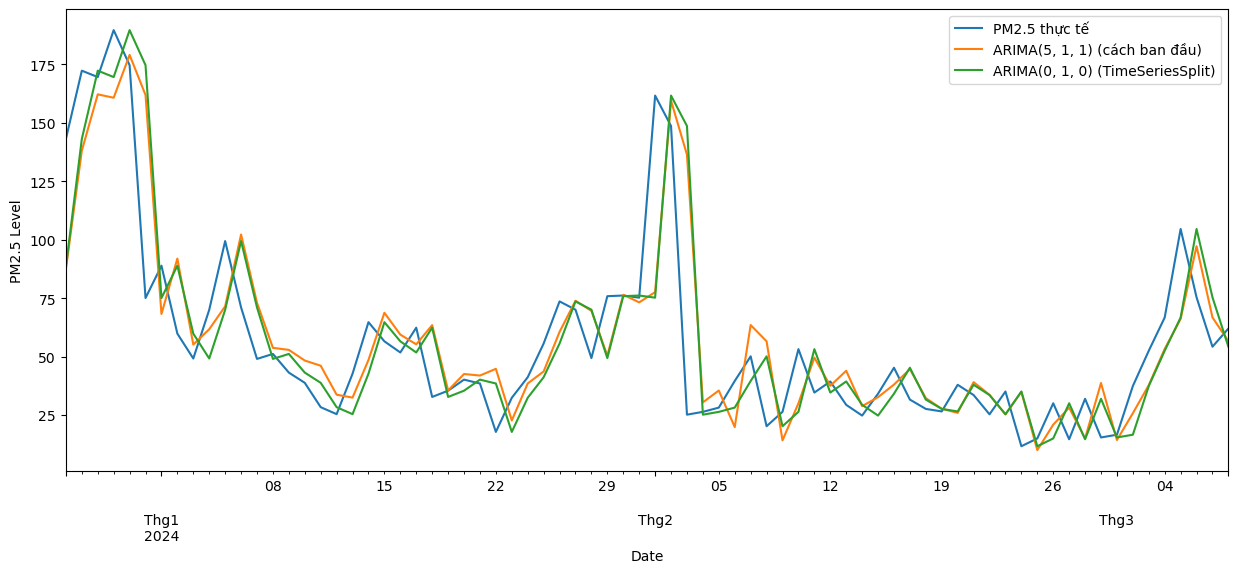

In [177]:
ax = df_pm25_test.plot(label='PM2.5 thực tế', figsize=(15, 6))
df_pm25_pred_wfv_original.plot(
    ax=ax, label=f'ARIMA{best_order_original} (cách ban đầu)'
)
df_pm25_pred_wfv_tscv.plot(
    ax=ax, label=f'ARIMA{best_order_tscv} (TimeSeriesSplit)'
)
plt.ylabel('PM2.5 Level')
plt.xlabel('Date')
plt.legend()
plt.show()

Biểu đồ so sánh PM2.5 thực tế với dự báo walk-forward từ hai cách chọn tham số: cách ban đầu và TimeSeriesSplit.